# Week 8: Randomness and simulation

[Open in Colab](https://colab.research.google.com/github/WSU-EconS431/site/blob/main/weeks/week08.ipynb) · [View on GitHub](https://github.com/WSU-EconS431/site/blob/main/weeks/week08.ipynb)

Some questions have no formula but can be answered by **simulation**: build the process in code, run it many times, and look at what happens. Simulation answers "how uncertain is this estimate?", "what does a shock to a model do to the *distribution* of outcomes?", and "does my formula agree with a brute-force check?"

**After this week you can:**

- draw random numbers reproducibly with `np.random.default_rng(seed)`
- see the law of large numbers and the central limit theorem happen
- estimate an expectation by Monte Carlo and report its standard error
- bootstrap a confidence interval for a statistic with no formula
- simulate a Markov chain and compare the long-run share with the stationary distribution
- push random shocks through a model you solve numerically (Week 6)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from pathlib import Path

## 1. Random numbers, reproducibly

A computer's "random" numbers come from a deterministic recipe started at a **seed**. The same seed gives the same numbers every run, which is what you want in a notebook: your results should not change when someone re-runs it. Create one generator, `rng`, and draw everything from it.

In [2]:
rng = np.random.default_rng(2027)
print("uniform on [0,1):", rng.random(3).round(3))
print("standard normal:  ", rng.normal(size=3).round(3))
print("dice rolls:       ", rng.integers(1, 7, size=10))
print("pick from a list: ", rng.choice(["low", "mid", "high"], size=5, p=[0.5, 0.3, 0.2]))

rng_a, rng_b = np.random.default_rng(5), np.random.default_rng(5)
print("same seed, same draws:", np.allclose(rng_a.random(4), rng_b.random(4)))

uniform on [0,1): [0.008 0.386 0.083]
standard normal:   [-2.152  1.212 -0.482]
dice rolls:        [4 2 1 4 4 4 1 1 5 1]
pick from a list:  ['low' 'high' 'low' 'high' 'mid']
same seed, same draws: True


## 2. The law of large numbers

The average of many independent draws settles down to the true mean. Here, the average of fair-die rolls (true mean 3.5) as the number of rolls grows:

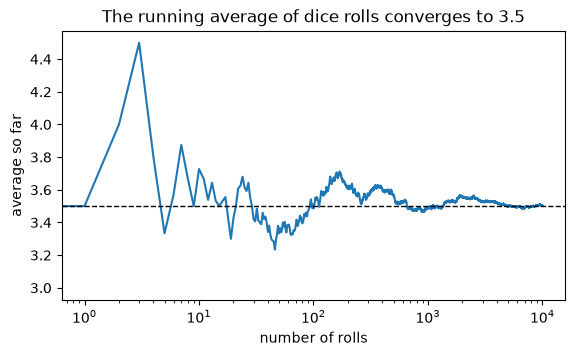

average after 10, 100, 10,000 rolls: 3.5 3.51 3.501


In [3]:
rng = np.random.default_rng(1)
rolls = rng.integers(1, 7, size=10_000)
running = np.cumsum(rolls) / np.arange(1, len(rolls) + 1)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(running)
ax.axhline(3.5, color="k", ls="--", lw=1)
ax.set_xscale("log"); ax.set_xlabel("number of rolls"); ax.set_ylabel("average so far")
ax.set_title("The running average of dice rolls converges to 3.5")
plt.show()
print("average after 10, 100, 10,000 rolls:", running[9].round(2), running[99].round(2), running[-1].round(3))

## 3. How wrong is a simulation? The standard error

A Monte Carlo estimate is itself random. If $\hat\mu$ is the average of $n$ independent draws with standard deviation $\sigma$, its **standard error** is $\sigma/\sqrt{n}$: to cut the error in half you need *four times* the draws.

Example: $\mathbb{E}[\max(X, Y)]$ for independent standard normals $X, Y$. The exact answer is $1/\sqrt{\pi} \approx 0.5642$, so we can check the simulation.

In [4]:
rng = np.random.default_rng(16)
for n in [100, 10_000, 1_000_000]:
    m = np.maximum(rng.normal(size=n), rng.normal(size=n))
    est, se = m.mean(), m.std(ddof=1) / np.sqrt(n)
    print(f"n = {n:>9,}: estimate {est:.4f},  standard error {se:.4f},  error vs exact {est - 1/np.sqrt(np.pi):+.4f}")

n =       100: estimate 0.6006,  standard error 0.0832,  error vs exact +0.0365
n =    10,000: estimate 0.5602,  standard error 0.0082,  error vs exact -0.0040
n = 1,000,000: estimate 0.5637,  standard error 0.0008,  error vs exact -0.0005


The errors are about one standard error in size, and the standard error shrinks by a factor of 10 each time $n$ grows by a factor of 100. Always report the standard error with a Monte Carlo number: without it, nobody knows how many digits to trust.

## 4. The central limit theorem

Averages of *any* independent draws with finite variance look normal when $n$ is large, even if the draws are very skewed. Here, draws from a heavily skewed distribution (exponential), averaged over 50 draws each:

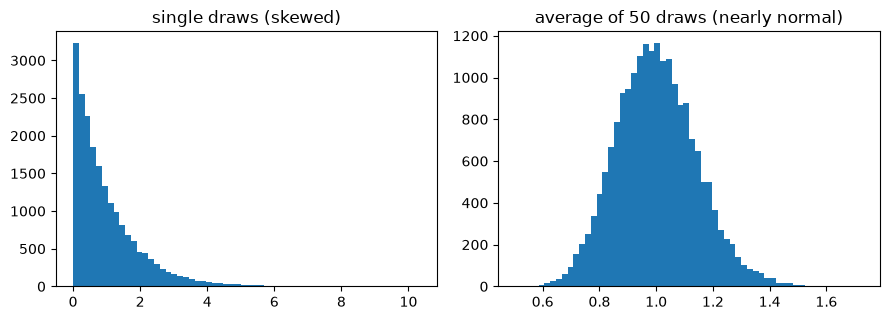

sd of a single draw: 0.989   sd of the average of 50: 0.142   (1/sqrt(50) = 0.141 )


In [5]:
rng = np.random.default_rng(3)
single = rng.exponential(size=20_000)
means = rng.exponential(size=(20_000, 50)).mean(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), sharey=False)
axes[0].hist(single, bins=60); axes[0].set_title("single draws (skewed)")
axes[1].hist(means, bins=60); axes[1].set_title("average of 50 draws (nearly normal)")
plt.tight_layout(); plt.show()
print("sd of a single draw:", single.std().round(3), "  sd of the average of 50:", means.std().round(3), "  (1/sqrt(50) =", round(1/np.sqrt(50), 3), ")")

## 5. The bootstrap

How uncertain is the average US real GDP growth rate over 1959–2009? There is a formula for the mean, but not for, say, the median or a quantile. The **bootstrap** needs no formula: resample your own data *with replacement* many times, recompute the statistic each time, and use the spread of those results as the uncertainty.

In [6]:
DATA = "../data" if Path("../data").exists() else "https://raw.githubusercontent.com/WSU-EconS431/site/main/data"
us = pd.read_csv(f"{DATA}/us_macro_1959_2009.csv")
growth = 400 * np.log(us["realgdp"]).diff().dropna().to_numpy()      # annualized quarterly growth, percent
print(f"{len(growth)} quarters; mean {growth.mean():.2f}%, median {np.median(growth):.2f}%")

rng = np.random.default_rng(8)
B = 5000
boot_mean = np.empty(B); boot_med = np.empty(B)
for b in range(B):
    resample = rng.choice(growth, size=len(growth), replace=True)
    boot_mean[b] = resample.mean(); boot_med[b] = np.median(resample)

se_formula = growth.std(ddof=1) / np.sqrt(len(growth))
print(f"mean:   bootstrap 95% interval {np.percentile(boot_mean, [2.5, 97.5]).round(2)},  formula {(growth.mean() + np.array([-1.96, 1.96]) * se_formula).round(2)}")
print(f"median: bootstrap 95% interval {np.percentile(boot_med, [2.5, 97.5]).round(2)}   (no simple formula)")

202 quarters; mean 3.10%, median 3.06%


mean:   bootstrap 95% interval [2.62 3.59],  formula [2.62 3.59]
median: bootstrap 95% interval [2.79 3.46]   (no simple formula)


For the mean, the bootstrap and the formula agree, which is the point of checking. For the median there is no easy formula, and the bootstrap gives an interval anyway. One caution: this bootstrap treats quarters as independent draws, which is a simplification for time series (growth in one quarter is not independent of the next), so treat the interval as a rough guide.

## 6. Simulating a Markov chain

Last week's recession chain, with $P$ estimated from the data. To **simulate** it, start in a state and at each step draw the next state using the current row of $P$. Over a long run, the share of time in recession should be close to the stationary distribution we computed last week (about 19%), and the average recession spell should be close to the expected duration (about 4.75 quarters).

In [7]:
P = np.array([[0.9512, 0.0488],
              [0.2105, 0.7895]])
rng = np.random.default_rng(11)
T = 20_000
state = np.zeros(T, dtype=int)
for t in range(1, T):
    state[t] = rng.choice(2, p=P[state[t - 1]])

# lengths of the runs of consecutive recession quarters
runs, length = [], 0
for s_ in state:
    if s_ == 1:
        length += 1
    elif length > 0:
        runs.append(length); length = 0
print(f"share of time in recession: {state.mean():.3f}   (stationary distribution: {0.0488 / (0.0488 + 0.2105):.3f})")
print(f"average recession spell: {np.mean(runs):.2f} quarters over {len(runs)} recessions   (formula: {1 / (1 - P[1, 1]):.2f})")

share of time in recession: 0.184   (stationary distribution: 0.188)
average recession spell: 4.57 quarters over 804 recessions   (formula: 4.75)


## 7. Random shocks through a model

Week 6's market (without a tax) has demand $Q_d = A P^{-\varepsilon}$ and supply $Q_s = B P^{\gamma}$. Suppose demand is uncertain: $A = 300\,e^{0.2 z}$ with $z$ standard normal. What is the distribution of the equilibrium price? We solve the market for each of many draws of $A$, with `brentq` (in this simple case there is a formula, $P = (A/B)^{1/(\varepsilon+\gamma)}$, which lets us check the simulation).

largest gap between solver and formula: 0.0
mean price 4.547 (price at the average shock: 4.527),  5th to 95th percentile: [3.97 5.19]
share of draws with price above 5: 0.114


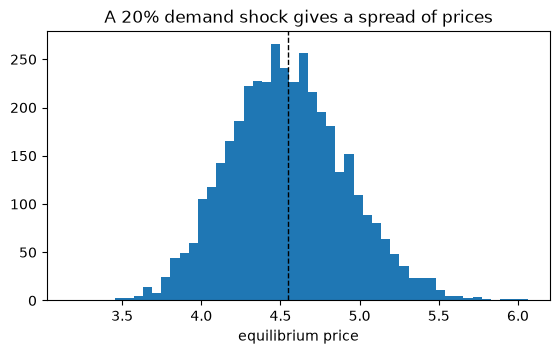

In [8]:
eps, Bs, gam = 1.8, 8, 0.6
rng = np.random.default_rng(21)
n = 4000
A_draws = 300 * np.exp(0.2 * rng.normal(size=n))
prices = np.array([brentq(lambda p, A=A: A * p ** (-eps) - Bs * p ** gam, 0.01, 500) for A in A_draws])
formula = (A_draws / Bs) ** (1 / (eps + gam))
print("largest gap between solver and formula:", np.abs(prices - formula).max().round(10))
print(f"mean price {prices.mean():.3f} (price at the average shock: {(300 / Bs) ** (1 / (eps + gam)):.3f}),  5th to 95th percentile: {np.percentile(prices, [5, 95]).round(2)}")
print("share of draws with price above 5:", (prices > 5).mean().round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.hist(prices, bins=50)
ax.axvline(prices.mean(), color="k", ls="--", lw=1)
ax.set_xlabel("equilibrium price"); ax.set_title("A 20% demand shock gives a spread of prices")
plt.show()

A symmetric shock to log demand gives a *skewed* distribution of prices (the mean is slightly above the price at the average shock), and the question "how likely is a price above 5?" has an answer that no point forecast can give. That is what simulation is for.

## 8. In-class work

**There is no Lab 8: the midterm is this week.** Week 7's lab was the practice run. After the midterm, the second class session is a regular lecture on this notebook.

## This week

- Read *Python Programming for Economics and Finance*: [FC 10. LLN and CLT](https://intro.quantecon.org/lln_clt_intro.html), and review Weeks 1–7 for the midterm.
- **PS08** (Monte Carlo, bootstrap, a simulated chain, a market with shocks) is in the `ps08` folder of your repo.
- Next: Module 4 begins.